دانلود دیتاست

In [1]:
import os

# ۱. تنظیم توکن Kaggle شما
os.environ['KAGGLE_USERNAME'] = "YOUR_KAGGLE_USERNAME" # نام کاربری کگل خود را وارد کنید
os.environ['KAGGLE_KEY'] = "KGAT_da58061e30529fdc1551bbf0b296caff"

dataset_slug = "andrewmvd/helmet-detection"
zip_name = "helmet-detection.zip"
extract_path = "/content/helmet_dataset"

print("⏳ در حال دانلود دیتاسِت کلاه ایمنی از کگل...")
!kaggle datasets download -d {dataset_slug}

print("📦 دانلود تمام شد. در حال استخراج فایل‌ها...")
!mkdir -p {extract_path}
!unzip -q {zip_name} -d {extract_path}

# حذف فایل زیپ برای آزادسازی حافظه
if os.path.exists(zip_name):
    os.remove(zip_name)

print("✨ فایل‌ها استخراج شدند!")
print("📂 محتویات پوشه دیتاست:")
print(os.listdir(extract_path))

⏳ در حال دانلود دیتاسِت کلاه ایمنی از کگل...
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/helmet-detection
License(s): CC0-1.0
100% 391M/391M [00:03<00:00, 121MB/s]

📦 دانلود تمام شد. در حال استخراج فایل‌ها...
✨ فایل‌ها استخراج شدند!
📂 محتویات پوشه دیتاست:
['annotations', 'images']


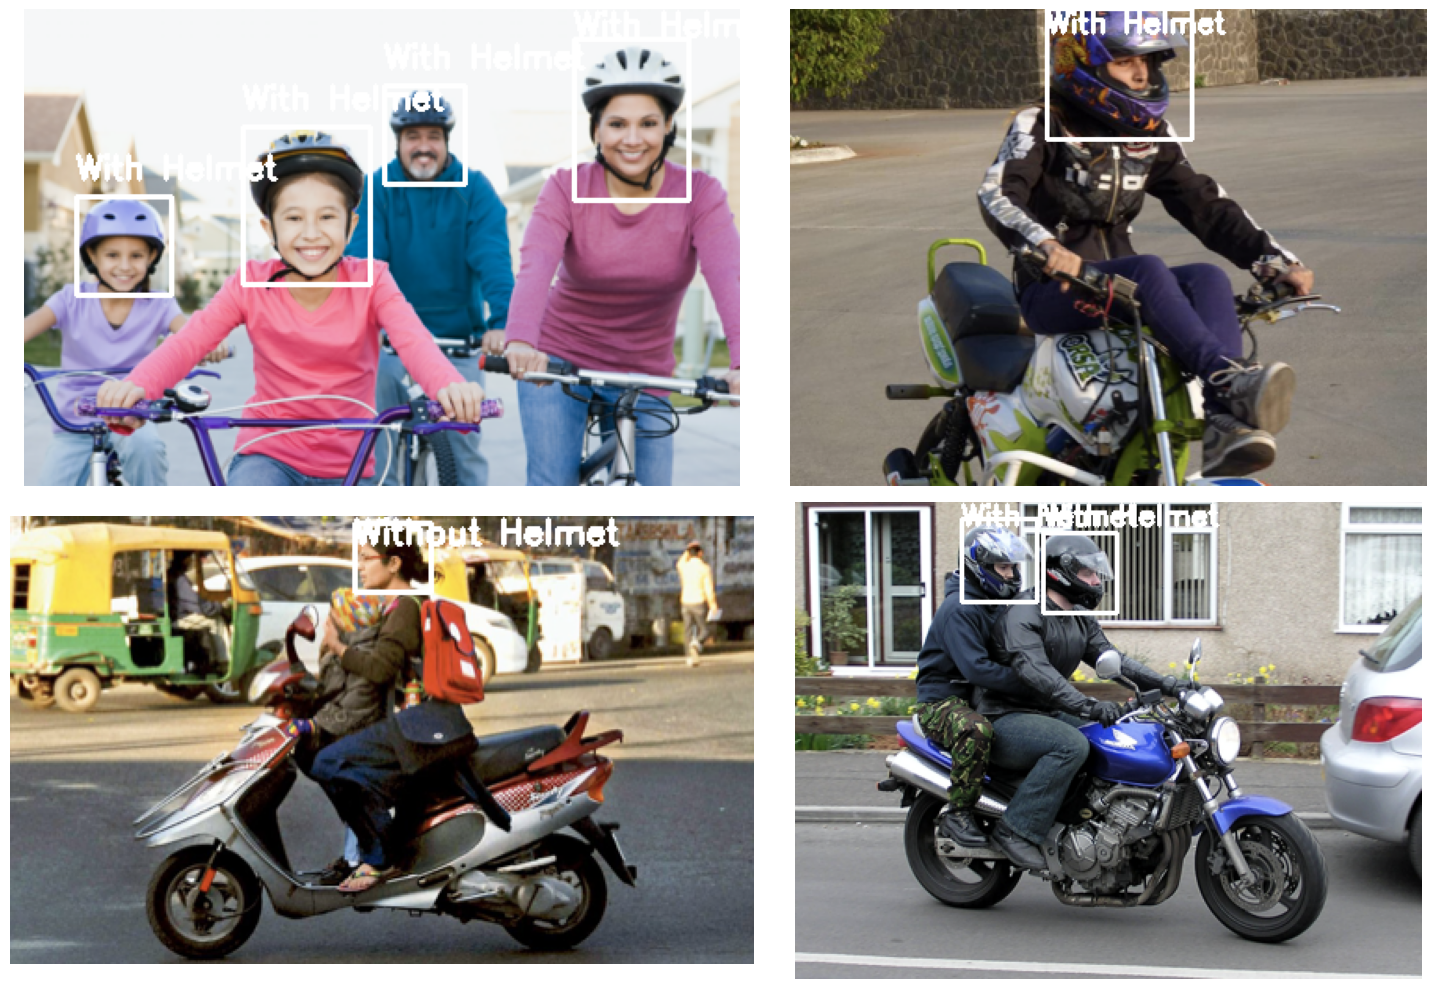

In [2]:
import os
import cv2
import glob
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# مسیر پوشه‌های دیتاست
images_dir = "/content/helmet_dataset/images"
annotations_dir = "/content/helmet_dataset/annotations"

# دریافت لیست تمامی فایل‌های XML
xml_files = sorted(glob.glob(os.path.join(annotations_dir, "*.xml")))

# تنظیمات رنگ کادرها (سبز برای با کلاه، قرمز برای بدون کلاه)
colors = {
    "With helmet": (0, 255, 0),
    "Without helmet": (255, 0, 0)
}

# نمایش ۴ تصویر نمونه
plt.figure(figsize=(15, 10))

for i, xml_path in enumerate(xml_files[:4]):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    # پیدا کردن اسم تصویر مربوطه
    img_name = root.find("filename").text
    img_path = os.path.join(images_dir, img_name)

    # لود تصویر
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # استخراج کادرها و کلاس‌ها از XML
    for obj in root.findall("object"):
        label = obj.find("name").text
        bndbox = obj.find("bndbox")

        xmin = int(bndbox.find("xmin").text)
        ymin = int(bndbox.find("ymin").text)
        xmax = int(bndbox.find("xmax").text)
        ymax = int(bndbox.find("ymax").text)

        # رسم مستطیل و متن
        color = colors.get(label, (255, 255, 255))
        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), color, 2)
        cv2.putText(image, label, (xmin, max(ymin - 10, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    # رسم در خروجی
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
import os
import glob
import shutil
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

# ۱. تعریف مسیرها
base_dir = "/content/helmet_dataset"
xml_dir = os.path.join(base_dir, "annotations")
img_dir = os.path.join(base_dir, "images")
output_dir = "/content/yolo_dataset"

# تعریف کلاس‌ها (با اندیس 0 و 1)
classes = ["With helmet", "Without helmet"]

# ۲. تابع تبدیل XML به TXT با فرمت YOLO
def convert_annotation(xml_file, output_txt_path):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    size = root.find('size')
    w = int(size.find('width').text)
    h = int(size.find('height').text)

    lines = []
    for obj in root.findall('object'):
        cls_name = obj.find('name').text
        if cls_name not in classes:
            continue
        cls_id = classes.index(cls_name)

        xmlbox = obj.find('bndbox')
        xmin = float(xmlbox.find('xmin').text)
        xmax = float(xmlbox.find('xmax').text)
        ymin = float(xmlbox.find('ymin').text)
        ymax = float(xmlbox.find('ymax').text)

        # نرمال‌سازی مختصات برای YOLO
        x_center = ((xmin + xmax) / 2.0) / w
        y_center = ((ymin + ymax) / 2.0) / h
        width = (xmax - xmin) / w
        height = (ymax - ymin) / h

        lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

    with open(output_txt_path, 'w') as f:
        f.writelines(lines)

# ۳. ساخت پوشه‌های YOLO
for split in ['train', 'val']:
    os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

# ۴. تقسیم‌بندی داده‌ها (۸۰٪ آموزش، ۲۰٪ ارزیابی)
xml_files = sorted(glob.glob(os.path.join(xml_dir, "*.xml")))
train_xmls, val_xmls = train_test_split(xml_files, test_size=0.2, random_state=42)

def process_split(file_list, split_name):
    for xml_path in file_list:
        file_id = os.path.splitext(os.path.basename(xml_path))[0]

        # پیدا کردن تصویر مربوطه
        img_path = os.path.join(img_dir, f"{file_id}.png")
        if not os.path.exists(img_path):
            img_path = os.path.join(img_dir, f"{file_id}.jpg")

        if os.path.exists(img_path):
            # کپی تصویر
            shutil.copy(img_path, os.path.join(output_dir, 'images', split_name, os.path.basename(img_path)))
            # تبدیل و ذخیره لیبل TXT
            txt_path = os.path.join(output_dir, 'labels', split_name, f"{file_id}.txt")
            convert_annotation(xml_path, txt_path)

process_split(train_xmls, 'train')
process_split(val_xmls, 'val')

# ۵. ساخت فایل کانفیگ data.yaml
yaml_content = f"""path: {output_dir}
train: images/train
val: images/val

names:
  0: With helmet
  1: Without helmet
"""

with open(os.path.join(output_dir, "data.yaml"), "w") as f:
    f.write(yaml_content)

print("✅ تبدیل فرمت و ساخت دیتاست YOLO با موفقیت انجام شد!")

✅ تبدیل فرمت و ساخت دیتاست YOLO با موفقیت انجام شد!


In [4]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.6 MB/s eta 0:00:00


In [8]:
import os
import glob
import shutil
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

base_dir = "/content/helmet_dataset"
xml_dir = os.path.join(base_dir, "annotations")
img_dir = os.path.join(base_dir, "images")
output_dir = "/content/yolo_dataset"

# ۱. کشف اسامی دقیق کلاس‌های موجود در فایل‌های XML
found_classes = set()
xml_files = sorted(glob.glob(os.path.join(xml_dir, "*.xml")))

for xml_file in xml_files:
    tree = ET.parse(xml_file)
    root = tree.getroot()
    for obj in root.findall('object'):
        cls_name = obj.find('name').text.strip()
        found_classes.add(cls_name)

classes = sorted(list(found_classes))
print(f"🔍 کلاس‌های واقعی کشف‌شده در دیتاست شما: {classes}")

# ۲. حذف و ساخت مجدد پوشه خروجی
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

for split in ['train', 'val']:
    os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

# ۳. تابع تبدیل XML به TXT
def convert_annotation(xml_file, output_txt_path):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    size = root.find('size')
    w = int(size.find('width').text)
    h = int(size.find('height').text)

    lines = []
    for obj in root.findall('object'):
        cls_name = obj.find('name').text.strip()
        if cls_name not in classes:
            continue
        cls_id = classes.index(cls_name)

        xmlbox = obj.find('bndbox')
        xmin = float(xmlbox.find('xmin').text)
        xmax = float(xmlbox.find('xmax').text)
        ymin = float(xmlbox.find('ymin').text)
        ymax = float(xmlbox.find('ymax').text)

        x_center = ((xmin + xmax) / 2.0) / w
        y_center = ((ymin + ymax) / 2.0) / h
        width = (xmax - xmin) / w
        height = (ymax - ymin) / h

        lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

    with open(output_txt_path, 'w') as f:
        f.writelines(lines)

# ۴. تقسیم‌بندی و انتقال داده‌ها
train_xmls, val_xmls = train_test_split(xml_files, test_size=0.2, random_state=42)

def process_split(file_list, split_name):
    for xml_path in file_list:
        file_id = os.path.splitext(os.path.basename(xml_path))[0]

        img_path = None
        for ext in ['.png', '.jpg', '.jpeg', '.PNG', '.JPG']:
            possible_path = os.path.join(img_dir, f"{file_id}{ext}")
            if os.path.exists(possible_path):
                img_path = possible_path
                break

        if img_path:
            shutil.copy(img_path, os.path.join(output_dir, 'images', split_name, os.path.basename(img_path)))
            txt_path = os.path.join(output_dir, 'labels', split_name, f"{file_id}.txt")
            convert_annotation(xml_path, txt_path)

process_split(train_xmls, 'train')
process_split(val_xmls, 'val')

# ۵. ساخت فایل data.yaml با کلاس‌های واقعی
names_dict = "\n".join([f"  {i}: {cls}" for i, cls in enumerate(classes)])
yaml_content = f"""path: {output_dir}
train: images/train
val: images/val

names:
{names_dict}
"""

with open(os.path.join(output_dir, "data.yaml"), "w") as f:
    f.write(yaml_content)

# ۶. بررسی محتوای یکی از فایل‌های TXT
sample_txt = glob.glob(os.path.join(output_dir, 'labels/train/*.txt'))[0]
with open(sample_txt, 'r') as f:
    sample_content = f.read()

print("✅ دیتاست با موفقیت بازسازی شد!")
print(f"📄 نمونه محتوای اولین فایل TXT:\n{sample_content if sample_content else '❌ همچنان خالی است!'}")

🔍 کلاس‌های واقعی کشف‌شده در دیتاست شما: ['With Helmet', 'Without Helmet']
✅ دیتاست با موفقیت بازسازی شد!
📄 نمونه محتوای اولین فایل TXT:
0 0.161250 0.243396 0.177500 0.283019
0 0.490000 0.318868 0.105000 0.200000



In [9]:
from ultralytics import YOLO

# ۱. بارگذاری مدل پیش‌آموخته سبک YOLOv8
model = YOLO('yolov8n.pt')

# ۲. شروع آموزش
results = model.train(
    data='/content/yolo_dataset/data.yaml',
    epochs=25,
    imgsz=640,
    batch=16,
    name='helmet_detection_model'
)

print("🎉 آموزش مدل با موفقیت به پایان رسید!")

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_detection_model-3, nbs=64, nms=False, opset=


image 1/1 /content/yolo_dataset/images/val/BikesHelmets197.png: 512x640 1 Without Helmet, 58.4ms
Speed: 2.7ms preprocess, 58.4ms inference, 1.7ms postprocess per image at shape (1, 3, 512, 640)

image 1/1 /content/yolo_dataset/images/val/BikesHelmets518.png: 448x640 4 With Helmets, 63.7ms
Speed: 2.7ms preprocess, 63.7ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /content/yolo_dataset/images/val/BikesHelmets618.png: 416x640 4 With Helmets, 77.7ms
Speed: 2.7ms preprocess, 77.7ms inference, 1.9ms postprocess per image at shape (1, 3, 416, 640)

image 1/1 /content/yolo_dataset/images/val/BikesHelmets462.png: 288x640 1 With Helmet, 2 Without Helmets, 64.9ms
Speed: 1.8ms preprocess, 64.9ms inference, 3.4ms postprocess per image at shape (1, 3, 288, 640)


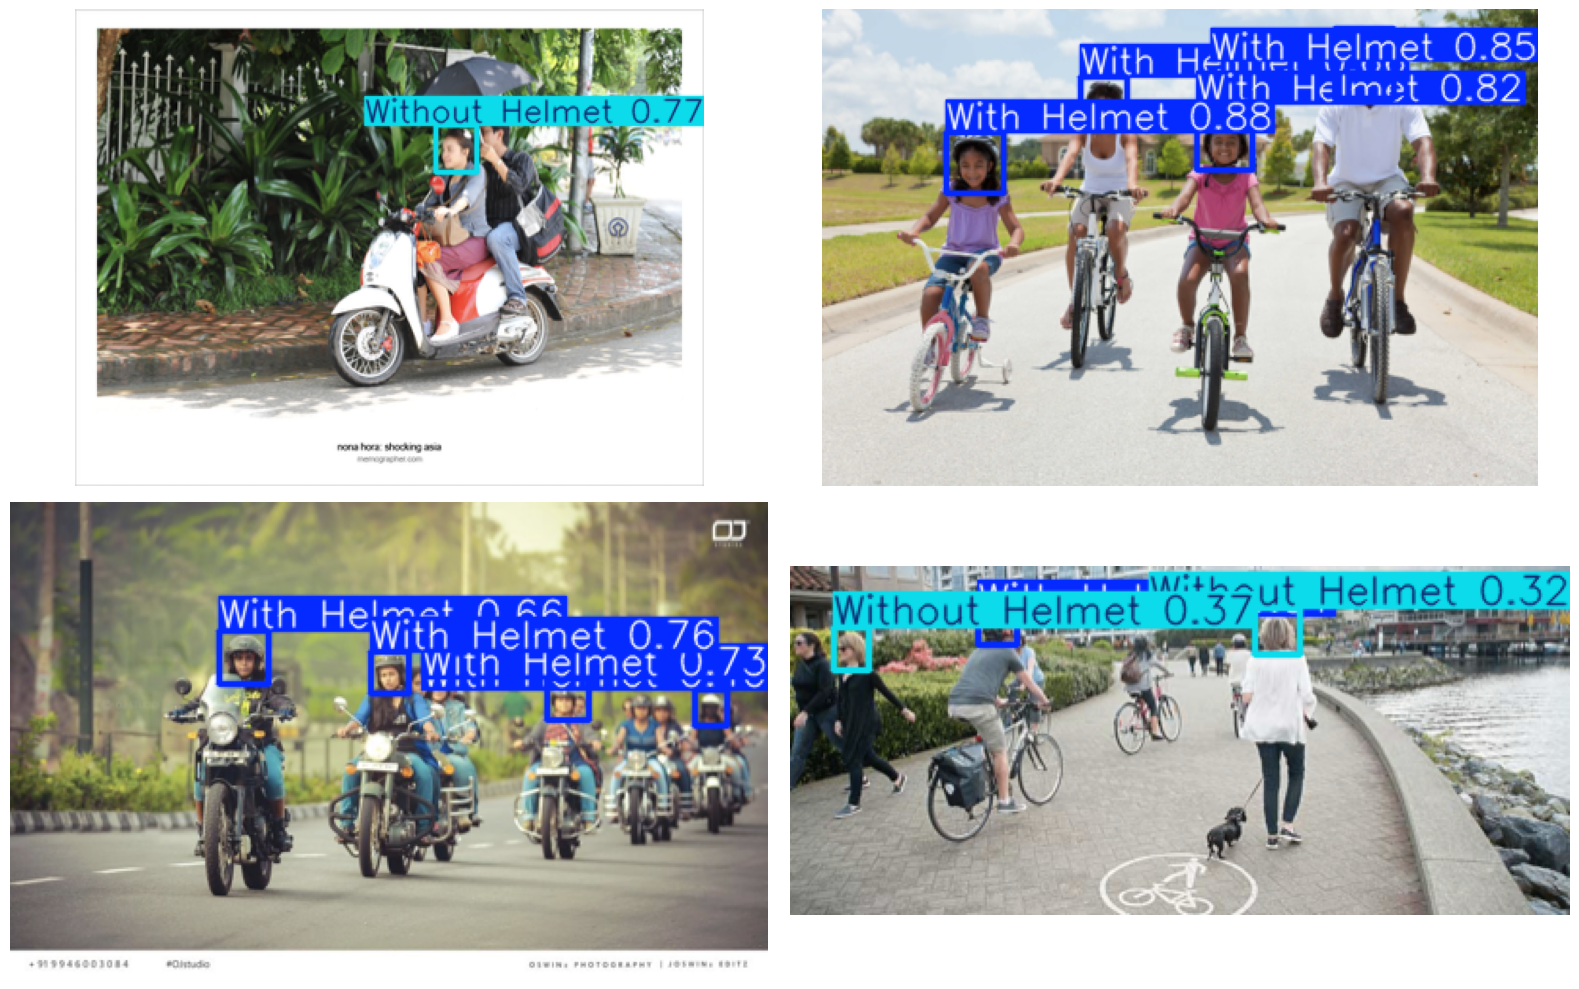

In [10]:
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ۱. بارگذاری مدل آموزش‌دیده (به آدرس دقیق مدل توجه کنید)
best_model_path = '/content/runs/detect/helmet_detection_model-3/weights/best.pt'
model = YOLO(best_model_path)

# ۲. انتخاب ۴ تصویر از پوشه val
val_images = glob.glob('/content/yolo_dataset/images/val/*.*')[:4]

# ۳. اجرای پیش‌بینی و رسم خروجی
plt.figure(figsize=(16, 10))

for i, img_path in enumerate(val_images):
    # پیش‌بینی با حد آستانه دقت ۰.۳
    results = model.predict(source=img_path, conf=0.30)

    # دریافت تصویر کادربندی‌شده
    res_plotted = results[0].plot()
    res_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 2, i + 1)
    plt.imshow(res_rgb)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
from google.colab import files

files.download('/content/runs/detect/helmet_detection_model-3/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>